# Getting started with Qiskit
### Circuits, observables and the Estimator: a warm-up for the phase-transition notebook

This notebook is a hands-on introduction to the parts of Qiskit that you will use in *Quantum phase transitions with Qiskit*. You will learn how to:

1. build a quantum circuit and look at the state it prepares;
2. measure it many times, as a real quantum computer does;
3. write observables, such as $Z_0 Z_1$, and compute their expectation values with the **Estimator**;
4. build circuits with adjustable angles, and combine everything into a tiny variational algorithm (VQE).

**What you need to know:** basic Python and NumPy, and the basics of quantum computing: qubits, kets like $|0\rangle$ and $|1\rangle$, gates and measurements. No previous experience with Qiskit is needed.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

import qiskit
from qiskit import QuantumCircuit
from qiskit.circuit import Parameter, ParameterVector
from qiskit.primitives import StatevectorEstimator, StatevectorSampler
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit.visualization import plot_bloch_multivector, plot_histogram

print("Qiskit version:", qiskit.__version__)

plt.rcParams.update({"figure.figsize": (6.4, 4.2), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

Qiskit version: 2.6.1


Qiskit can print a state as a list of numbers, but a sum of kets is easier to read. The function below prints the state prepared by a circuit in this form, together with the probability of each measurement outcome. Don't worry, you don't need to understand exactly how it works, consider them helper functions.

In [2]:
def format_amplitude(z):
    # A complex number as text, without the parts that are zero
    if abs(z.imag) < 1e-10:
        return f"{z.real:+.3f}"
    if abs(z.real) < 1e-10:
        return f"{z.imag:+.3f}i"
    return f"({z.real:+.3f} {z.imag:+.3f}i)"


def show_state(circuit):
    # Print the state prepared by `circuit` (starting from |00...0>) as a sum of kets,
    # with the probability of each outcome. Amplitudes equal to zero are skipped.
    state = Statevector(circuit)
    n = state.num_qubits
    for index, amplitude in enumerate(state.data):
        if abs(amplitude) > 1e-10:
            bits = format(index, f"0{n}b")  # Qiskit's labels: qubit 0 is the rightmost bit
            print(f"{format_amplitude(amplitude):>18} |{bits}⟩    probability {abs(amplitude)**2:.3f}")

## 1. Your first circuit

In Qiskit, a quantum circuit is a `QuantumCircuit` object. You create it by giving the number of qubits, then you add gates one at a time by calling methods named after the gates. The number in parentheses says which qubit the gate acts on. Qubits are numbered from 0, and they all start in $|0\rangle$.

In [3]:
qc = QuantumCircuit(1)  # a circuit with one qubit, which starts in |0>
qc.x(0)                 # apply the X gate (the quantum NOT) to qubit 0
qc.draw()               # draw the circuit

┌───┐
q: ┤ X ├
   └───┘

`draw()` draws the circuit with text characters.

To find out which state the circuit prepares, we can simulate it with `Statevector`:

In [4]:
state = Statevector(qc)
print(state)

Statevector([0.+0.j, 1.+0.j],
            dims=(2,))


The state of $N$ qubits is a list of $2^N$ complex numbers, the **amplitudes**. Here there are two of them, for $|0\rangle$ and $|1\rangle$, and the state is $X|0\rangle = |1\rangle$. With our helper function:

In [5]:
show_state(qc)

            +1.000 |1⟩    probability 1.000


`Statevector` computes all the $2^N$ amplitudes exactly, on your computer. That is perfect for learning and for small systems (the phase-transition notebook uses it to check its results for up to 10 qubits), but impossible for large ones: 50 qubits would need about 18 million GB of memory. This is one of the reasons to build quantum computers.

## 2. Superposition and the Bloch sphere

The Hadamard gate $H$ creates an equal superposition: $H|0\rangle = |+\rangle = \frac{1}{\sqrt2}\left(|0\rangle + |1\rangle\right)$.

In [6]:
qc = QuantumCircuit(1)
qc.h(0)
show_state(qc)

            +0.707 |0⟩    probability 0.500
            +0.707 |1⟩    probability 0.500


The state of a single qubit can be drawn as an arrow on the **Bloch sphere**: $|0\rangle$ points to the north pole, $|1\rangle$ to the south pole, and $|+\rangle$ along the $x$ axis.

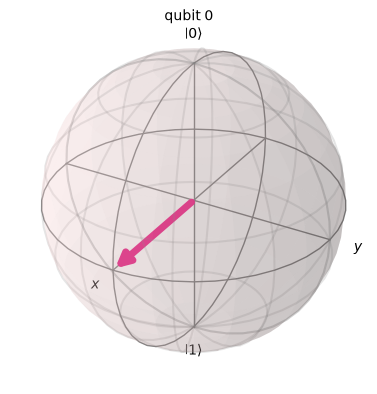

In [7]:
plot_bloch_multivector(Statevector(qc))

Here are some of the gates you can use (`q`, `c` and `t` are qubit numbers):

| Gate | Qiskit | What it does |
|---|---|---|
| $X$ | `qc.x(q)` | swaps $\vert 0\rangle$ and $\vert 1\rangle$ (the quantum NOT) |
| $Y$ | `qc.y(q)` | $\vert 0\rangle \to i\vert 1\rangle$ and $\vert 1\rangle \to -i\vert 0\rangle$ |
| $Z$ | `qc.z(q)` | changes the sign of $\vert 1\rangle$ |
| $H$ | `qc.h(q)` | $\vert 0\rangle \to \vert +\rangle$ and $\vert 1\rangle \to \vert -\rangle$ |
| $R_X(\theta)$, $R_Y(\theta)$, $R_Z(\theta)$ | `qc.rx(theta, q)`, `qc.ry(theta, q)`, `qc.rz(theta, q)` | rotate the Bloch arrow by the angle $\theta$ about the $x$, $y$ or $z$ axis |
| CNOT | `qc.cx(c, t)` | flips qubit `t` (the *target*) if qubit `c` (the *control*) is $\vert 1\rangle$ |
| CZ | `qc.cz(c, t)` | changes the sign of $\vert 11\rangle$ |
| SWAP | `qc.swap(q1, q2)` | swaps the states of two qubits |

On the Bloch sphere, $X$, $Y$ and $Z$ are rotations by $\pi$ about the corresponding axis.

**Try it.** The circuit below applies $H$, then $Z$, then $H$. Guess the final state before running it. Then try other combinations: $H$ twice, $X$ then $H$, ...

In [62]:
qc = QuantumCircuit(1)
qc.h(0)
qc.z(0)
qc.h(0)

print("The circuit is:")
print(qc.draw())
print("The state is:")
show_state(qc)

The circuit is:
   ┌───┐┌───┐┌───┐
q: ┤ H ├┤ Z ├┤ H ├
   └───┘└───┘└───┘
The state is:
            +1.000 |1⟩    probability 1.000


## 3. Rotation gates

The gates with an angle, such as $R_X(\theta)$, are the building blocks of variational algorithms: changing the angle changes the state continuously. In Qiskit the angle comes first, then the qubit: `qc.rx(theta, q)`.

$R_X(\theta)$ rotates the Bloch arrow by $\theta$ about the $x$ axis:

$$R_X(\theta)|0\rangle = \cos\tfrac{\theta}{2}\,|0\rangle - i \sin\tfrac{\theta}{2}\,|1\rangle ,$$

so the probability of measuring 1 is $\sin^2(\theta/2)$. Let's check it for many angles:

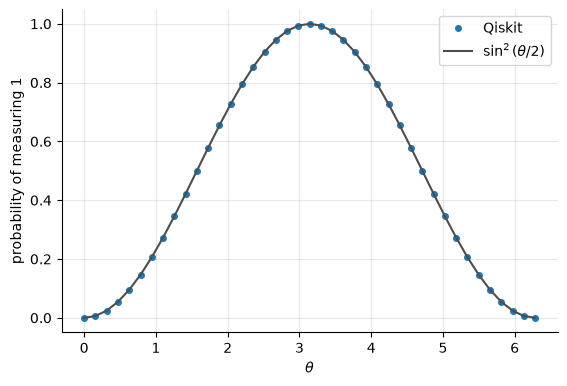

In [9]:
thetas = np.linspace(0, 2 * np.pi, 41)
prob_1 = []
for theta in thetas:
    qc = QuantumCircuit(1)
    qc.rx(theta, 0)
    prob_1.append(Statevector(qc).probabilities()[1])  # probabilities() returns [P(0), P(1)]

plt.plot(thetas, prob_1, "o", ms=4, label="Qiskit")
plt.plot(thetas, np.sin(thetas / 2) ** 2, color="0.3", label=r"$\sin^2(\theta/2)$")
plt.xlabel(r"$\theta$")
plt.ylabel("probability of measuring 1")
plt.legend()
plt.show()

$R_Z(\theta)$ is different: it only changes the *relative phase* of $|0\rangle$ and $|1\rangle$, so it never changes the probabilities of measuring 0 or 1. On the Bloch sphere it turns the arrow around the $z$ axis. Here $R_Z(\pi/2)$ turns $|+\rangle$, which points along $x$, into a state that points along $y$:

  (+0.500 -0.500i) |0⟩    probability 0.500
  (+0.500 +0.500i) |1⟩    probability 0.500


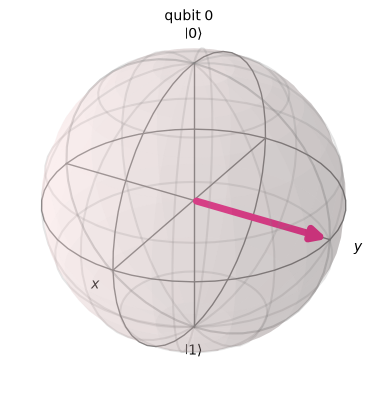

In [10]:
qc = QuantumCircuit(1)
qc.h(0)
qc.rz(np.pi / 2, 0)
show_state(qc)
plot_bloch_multivector(Statevector(qc))

The amplitudes are now complex, but the probabilities are still 1/2: a measurement in the usual basis cannot tell this state from $|+\rangle$.

Three rotations $R_Z$, $R_X$, $R_Z$ with independent angles can perform *any* rotation of the Bloch sphere (they are its "Euler angles"). This is why the circuit of the phase-transition notebook applies exactly this sequence to every qubit.

**Try it.** Find an angle $\theta$ for which $R_Y(\theta)|0\rangle$ gives 1 with probability 0.25. ($R_Y$ rotates about the $y$ axis; its probabilities are the same as for $R_X$.)

In [11]:
theta = 1.0  # change me
qc = QuantumCircuit(1)
qc.ry(theta, 0)
show_state(qc)

            +0.878 |0⟩    probability 0.770
            +0.479 |1⟩    probability 0.230


## 4. Several qubits, and how Qiskit orders them

With $N$ qubits, the basis states are labelled by bitstrings of length $N$, like $|010\rangle$. **Qiskit writes the bitstrings with qubit 0 on the right:** $|q_{N-1} \cdots q_1 q_0\rangle$. Many textbooks use the opposite order, so this is a classic source of confusion. Let's flip only qubit 0 of a three-qubit circuit:

In [12]:
qc = QuantumCircuit(3)
qc.x(0)
show_state(qc)
qc.draw()

            +1.000 |001⟩    probability 1.000


┌───┐
q_0: ┤ X ├
     └───┘
q_1: ─────
          
q_2: ─────

In the drawing qubit 0 is the top line, but in the bitstring it is the **rightmost** digit: the state is $|001\rangle$. The same convention is used for measurement results and for observables (Section 7).

**Try it.** Prepare the state in which qubits 1 and 2 are in $|1\rangle$ and qubit 0 is in $|0\rangle$. Which bitstring do you expect?

In [13]:
qc = QuantumCircuit(3)
# add your gates here
show_state(qc)

            +1.000 |000⟩    probability 1.000


## 5. Entanglement: the CNOT gate

The CNOT gate, `qc.cx(control, target)`, flips the target qubit when the control qubit is in $|1\rangle$. Let's check it on the four basis states, with qubit 0 as the control and qubit 1 as the target:

In [14]:
for q1 in [0, 1]:
    for q0 in [0, 1]:
        qc = QuantumCircuit(2)
        if q0 == 1:
            qc.x(0)
        if q1 == 1:
            qc.x(1)
        qc.cx(0, 1)  # control: qubit 0, target: qubit 1
        output = list(Statevector(qc).probabilities_dict())[0]  # the only outcome with nonzero probability
        print(f"input |{q1}{q0}⟩  ->  output |{output}⟩")

input |00⟩  ->  output |00⟩
input |01⟩  ->  output |11⟩
input |10⟩  ->  output |10⟩
input |11⟩  ->  output |01⟩


Remember the order: the right digit is qubit 0, the control. When it is 1, the left digit (qubit 1) is flipped.

Applied to a superposition, the CNOT creates **entanglement**. A Hadamard followed by a CNOT prepares the Bell state $\frac{1}{\sqrt2}\left(|00\rangle + |11\rangle\right)$:

In [15]:
bell = QuantumCircuit(2)
bell.h(0)
bell.cx(0, 1)
show_state(bell)
bell.draw()

            +0.707 |00⟩    probability 0.500
            +0.707 |11⟩    probability 0.500


┌───┐     
q_0: ┤ H ├──■──
     └───┘┌─┴─┐
q_1: ─────┤ X ├
          └───┘

### Think about it: a GHZ state on 4 qubits

The Bell state has a big brother on any number of qubits: the **GHZ state** (after Greenberger, Horne and Zeilinger). On 4 qubits it is

$$|\mathrm{GHZ}\rangle = \frac{1}{\sqrt2}\left(|0000\rangle + |1111\rangle\right),$$

so the four qubits are all 0 or all 1, with equal probability.

**Your turn.** Find a circuit that prepares this state from $|0000\rangle$, using only `h` and `cx`. Before you write any code, take a few minutes with pen and paper:

- The Bell circuit, `h(0)` followed by `cx(0, 1)`, makes qubits 0 and 1 agree. How can you bring qubits 2 and 3 into the agreement?
- What does a CNOT do to each term of a superposition?
- How many CNOTs do you need? Is there only one way?

Then write your circuit in the next cell, and run the cell after it to check it.

<details>
<summary>Hint 1 (click to open)</summary>

Start from the Bell circuit: on 4 qubits, `h(0)` and `cx(0, 1)` give $\frac{1}{\sqrt2}\left(|0000\rangle + |0011\rangle\right)$ (qubit 0 is the rightmost digit). What is left is to turn $|0011\rangle$ into $|1111\rangle$ without touching $|0000\rangle$.

</details>

<details>
<summary>Hint 2</summary>

A CNOT acts on each term of the superposition separately. In $|0000\rangle$ all the controls are 0, so nothing happens to this term. In $|0011\rangle$ qubits 0 and 1 are 1: a CNOT controlled by one of them flips its target in this term only.

</details>

**Bonus.** The check also prints the **depth** of your circuit: the number of time steps it needs, if gates on different qubits run at the same time. On a real device a shallower circuit accumulates fewer errors. Once yours works, can you find one with a smaller depth?

In [ ]:
ghz = QuantumCircuit(4)
# add your gates here

show_state(ghz)
ghz.draw()

            +1.000 |0000⟩    probability 1.000


q_0: 
     
q_1: 
     
q_2: 
     
q_3:

In [ ]:
# Check: does `ghz` prepare (|0000⟩ + |1111⟩)/√2?
ghz_target = (Statevector.from_label("0000") + Statevector.from_label("1111")) / np.sqrt(2)
if Statevector(ghz).equiv(ghz_target):
    print(f"Well done, this is the GHZ state! Your circuit has {ghz.count_ops().get('cx', 0)} CNOTs and depth {ghz.depth()}.")
else:
    print("Not yet: the state should be (|0000⟩ + |1111⟩)/√2, with nothing else. Have a look at the hints.")

Not yet: the state should be (|0000⟩ + |1111⟩)/√2, with nothing else. Have a look at the hints.


<details>
<summary>Solutions (don't open them immediately, give it a try)</summary>

**The idea.** After `h(0)` the state is $\frac{1}{\sqrt2}\left(|0000\rangle + |0001\rangle\right)$. A CNOT acts on each term separately: in $|0000\rangle$ all the controls are 0 and nothing happens, while in the other term a CNOT whose control is already 1 flips its target from 0 to 1. So each CNOT brings one more qubit into the agreement, and three of them give $\frac{1}{\sqrt2}\left(|0000\rangle + |1111\rangle\right)$. Fewer than three is impossible: a two-qubit gate links at most two groups of qubits, and we start with four separate ones.

There are several ways to choose the controls.

**1. A ladder:** each qubit passes the 1 on to its neighbour. Depth 4.

```python
N = 4
ghz = QuantumCircuit(N)
ghz.h(0)
for i in range(N - 1):
    ghz.cx(i, i + 1)  # CNOT between neighbours i and i+1
```

All the CNOTs act on neighbouring qubits. This is convenient on real devices, where each qubit is wired only to a few others, often its neighbours on a line or a grid.

**2. A fan:** qubit 0 controls all the CNOTs. Also depth 4: the three CNOTs share qubit 0, so they must run one after the other. And qubit 0 must be wired to all the others.

```python
ghz = QuantumCircuit(4)
ghz.h(0)
for target in [1, 2, 3]:
    ghz.cx(0, target)
```

**3. A tree:** once qubits 0 and 1 agree, both can be controls, at the same time. Depth 3.

```python
ghz = QuantumCircuit(4)
ghz.h(0)
ghz.cx(0, 1)
ghz.cx(0, 2)  # these two CNOTs act on different qubits,
ghz.cx(1, 3)  # so they run in the same time step
```

(The drawing shows the last two CNOTs one after the other, only because their vertical lines would overlap; `depth()` counts them as one step.) The number of qubits in agreement doubles at every step, so $N$ qubits need about $\log_2 N$ steps of CNOTs instead of $N - 1$: for 64 qubits, 6 instead of 63.

</details>

All the qubits agree, but they are all 0 or all 1 with equal probability. Keep this state in mind: in the phase-transition notebook, the ground state of the Ising chain in its ordered phase looks very much like it. The ladder of CNOTs of Solution 1 is also the entangling part of the circuit used there.

Before you go on, run the next cell. It builds the circuit `ghz` again, with the ladder, so that the rest of the notebook (Section 9) works even if your own circuit is not finished.

In [17]:
# The GHZ circuit used in the rest of the notebook: the ladder of Solution 1
N = 4
ghz = QuantumCircuit(N)
ghz.h(0)
for i in range(N - 1):
    ghz.cx(i, i + 1)  # CNOT between neighbours i and i+1
show_state(ghz)

            +0.707 |0000⟩    probability 0.500
            +0.707 |1111⟩    probability 0.500


## 6. Measuring: shots and the Sampler

A real quantum computer cannot show you the amplitudes. When you measure the qubits you get a single bitstring, picked at random with the probabilities given by the amplitudes. To learn something about the state, you prepare it and measure it many times; each repetition is called a **shot**.

In Qiskit, circuits with measurements are run by a **Sampler**. `StatevectorSampler` is a simulator that runs on your computer, with the same interface as the Sampler of a real device.

In [18]:
bell_measured = bell.copy()
bell_measured.measure_all()  # measure all the qubits at the end of the circuit
bell_measured.draw()

┌───┐      ░ ┌─┐   
   q_0: ┤ H ├──■───░─┤M├───
        └───┘┌─┴─┐ ░ └╥┘┌─┐
   q_1: ─────┤ X ├─░──╫─┤M├
             └───┘ ░  ║ └╥┘
meas: 2/══════════════╩══╩═
                      0  1

{'11': 497, '00': 503}


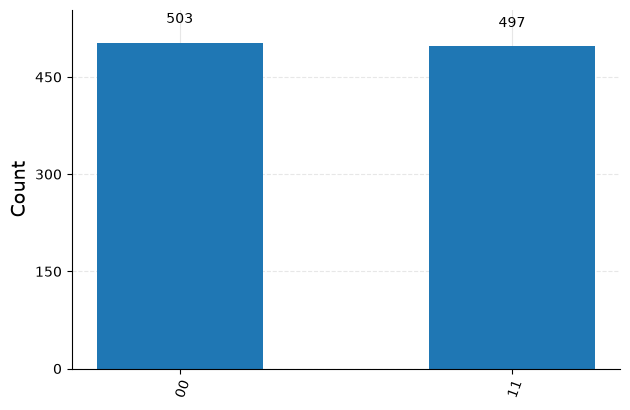

In [19]:
sampler = StatevectorSampler(seed=42)  # fixed seed: the same random outcomes every time

job = sampler.run([bell_measured], shots=1000)  # a list of circuits to run, and the number of shots
counts = job.result()[0].data.meas.get_counts()
print(counts)
plot_histogram(counts)

Step by step:

- `sampler.run([...])` takes a **list** of circuits (you can send many at once) and returns a *job*;
- `.result()` waits until the job is done and returns the results, one per circuit;
- `[0]` picks the result of the first circuit;
- `.data.meas` contains the measured bitstrings (`meas` is the name that `measure_all` gives to the measurements);
- `.get_counts()` counts how many times each bitstring appeared.

The Estimator below uses the same pattern, `run([...]).result()[0].data`.

As expected, only `00` and `11` appear, about 500 times each. **Try it:** change the number of shots to 10, 100 or 10000 (or remove the seed) and see how much the counts fluctuate.

**From shots to expectation values.** The average of a quantity over many shots estimates its **expectation value**. Take $Z_0$: each shot gives $+1$ if qubit 0 is found in 0, and $-1$ if it is found in 1. For $Z_0 Z_1$, each shot gives the product of the two values. Let's compute both averages from the counts above. Qubit 0 is the *last* character of each bitstring, and qubit 1 the one before it:

In [20]:
def z_value(bit):
    # measured bit "0" -> Z = +1,  bit "1" -> Z = -1
    return 1 if bit == "0" else -1


shots = sum(counts.values())
z0 = sum(z_value(bits[-1]) * n for bits, n in counts.items()) / shots
z0z1 = sum(z_value(bits[-1]) * z_value(bits[-2]) * n for bits, n in counts.items()) / shots
print(f"<Z0>    from {shots} shots: {z0:+.3f}    (exact value: 0)")
print(f"<Z0 Z1> from {shots} shots: {z0z1:+.3f}    (exact value: 1)")

<Z0>    from 1000 shots: +0.006    (exact value: 0)
<Z0 Z1> from 1000 shots: +1.000    (exact value: 1)


$\langle Z_0\rangle$ is close to its exact value 0, but not equal to it: with a finite number of shots there is always a statistical error, which shrinks like $1/\sqrt{\text{shots}}$. $\langle Z_0 Z_1\rangle$ is exactly 1, because the two qubits always agree.

Computing expectation values by hand like this quickly gets tedious: that is the job of the Estimator. But first we need a way to write observables.

## 7. Observables: Pauli strings with `SparsePauliOp`

Physical quantities, like the energy or the magnetization, are represented by **observables** (Hermitian operators). On a quantum computer they are usually written as sums of **Pauli strings**: products of $I$, $X$, $Y$ and $Z$ acting on the different qubits, each multiplied by a number. For instance, the energy of two spins in a magnetic field along $x$, which is the two-qubit version of the Ising model of the phase-transition notebook, is

$$H = -Z_0 Z_1 - h\,(X_0 + X_1).$$

In Qiskit, observables are `SparsePauliOp` objects. A single Pauli string is written as a text label with **one letter per qubit, and qubit 0 on the right**, as for bitstrings:

In [21]:
ZZ = SparsePauliOp("ZZ")  # Z on qubit 1 and Z on qubit 0
X0 = SparsePauliOp("IX")  # X on qubit 0, and nothing (the identity I) on qubit 1
X1 = SparsePauliOp("XI")  # X on qubit 1
print(X0)
print(X0.to_matrix().real)  # its 4x4 matrix, I ⊗ X (real, so we drop the zero imaginary parts)

SparsePauliOp(['IX'],
              coeffs=[1.+0.j])
[[0. 1. 0. 0.]
 [1. 0. 0. 0.]
 [0. 0. 0. 1.]
 [0. 0. 1. 0.]]


Sums of Pauli strings can be built in two ways. The second one lists only the qubits on which something happens, which is handier for long chains. It is the one used in the phase-transition notebook.

In [22]:
h = 0.5

# 1) a list of (label, coefficient), with one letter per qubit
H = SparsePauliOp.from_list([("ZZ", -1.0), ("IX", -h), ("XI", -h)])
print(H)

# 2) a list of (Paulis, the qubits they act on, coefficient), and the total number of qubits
H = SparsePauliOp.from_sparse_list([("ZZ", [0, 1], -1.0), ("X", [0], -h), ("X", [1], -h)], num_qubits=2)
print(H)

SparsePauliOp(['ZZ', 'IX', 'XI'],
              coeffs=[-1. +0.j, -0.5+0.j, -0.5+0.j])
SparsePauliOp(['ZZ', 'IX', 'XI'],
              coeffs=[-1. +0.j, -0.5+0.j, -0.5+0.j])


Observables can be added, multiplied by numbers, and multiplied together with `@` (the product of operators, like a matrix product). `simplify()` collects equal terms. For example, here are the magnetization $M = \frac12(Z_0 + Z_1)$ and its square:

In [23]:
Z0 = SparsePauliOp.from_sparse_list([("Z", [0], 1.0)], num_qubits=2)
Z1 = SparsePauliOp.from_sparse_list([("Z", [1], 1.0)], num_qubits=2)

M = 0.5 * (Z0 + Z1)
M2 = (M @ M).simplify()
print("M   =", M)
print("M^2 =", M2)

M   = SparsePauliOp(['IZ', 'ZI'],
              coeffs=[0.5+0.j, 0.5+0.j])
M^2 = SparsePauliOp(['II', 'ZZ'],
              coeffs=[0.5+0.j, 0.5+0.j])


Since $Z^2 = I$, $M^2 = \frac12\left(I + Z_0 Z_1\right)$, which is what Qiskit found. The phase-transition notebook builds $M$ and $M^2$ for $N$ qubits in exactly this way.

With `to_matrix()` you can always fall back on linear algebra. For example, the possible energies of $H$ are the eigenvalues of its $4\times4$ matrix:

In [24]:
print("matrix of H:\n", H.to_matrix().real)
print("eigenvalues:", np.linalg.eigvalsh(H.to_matrix()).round(4))

matrix of H:
 [[-1.  -0.5 -0.5  0. ]
 [-0.5  1.   0.  -0.5]
 [-0.5  0.   1.  -0.5]
 [ 0.  -0.5 -0.5 -1. ]]
eigenvalues: [-1.4142 -1.      1.      1.4142]


## 8. Expectation values

The **expectation value** $\langle\psi|O|\psi\rangle$ is the average of the results you would get by measuring the observable $O$ many times on the state $|\psi\rangle$. With a `Statevector` it can be computed exactly. Let's do it for the Bell state:

In [25]:
psi = Statevector(bell)
for label in ["IZ", "ZI", "ZZ", "IX", "XX"]:
    value = psi.expectation_value(SparsePauliOp(label))  # a complex number, with zero imaginary part
    print(f"<{label}> = {value.real:+.3f}")

<IZ> = +0.000
<ZI> = +0.000
<ZZ> = +1.000
<IX> = +0.000
<XX> = +1.000


$\langle Z_0\rangle = \langle Z_1\rangle = 0$: each qubit on its own is completely random. But $\langle Z_0 Z_1\rangle = 1$: the two are perfectly correlated (and so are $X_0$ and $X_1$).

This is the "subtlety" that you will meet in Section 5 of the phase-transition notebook: in an ordered chain the average magnetization $\langle M\rangle$ can be zero even though all the spins agree, so one measures $\langle M^2\rangle$ instead. Exercise 2 lets you check it.

## 9. The Estimator

The **Estimator** computes expectation values of observables in the states prepared by circuits. It does everything quantum in the phase-transition notebook. `StatevectorEstimator` computes the expectation values exactly, with a statevector simulation. A real quantum computer has an Estimator with the same interface, which estimates them from shots, so the code does not change.

Like the Sampler, the Estimator takes a list of tasks. Each one is a tuple `(circuit, observable)`, or `(circuit, observable, parameter values)` (see Section 10), which Qiskit calls a **PUB** (*primitive unified bloc*):

In [26]:
estimator = StatevectorEstimator()

job = estimator.run([(bell, SparsePauliOp("ZZ"))])  # a list with one PUB: (circuit, observable)
result = job.result()   # the results, one per PUB
pub_result = result[0]  # the result of the first (and here only) PUB
print("expectation value:", pub_result.data.evs)
print("standard error:   ", pub_result.data.stds)

expectation value: 0.9999999999999998
standard error:    0.0


`evs` stands for *expectation values*: here 1, up to a tiny rounding error of the computer. The standard error is zero because the simulation is exact. Usually everything is written in one line:

In [27]:
print(estimator.run([(bell, SparsePauliOp("ZZ"))]).result()[0].data.evs)

0.9999999999999998


**Several observables at once.** Give a list of observables, and you get an array with one expectation value for each of them:

In [28]:
observables = [SparsePauliOp(label) for label in ["IZ", "ZI", "ZZ", "XX"]]
evs = estimator.run([(bell, observables)]).result()[0].data.evs
print(evs)

[0. 0. 1. 1.]


The phase-transition notebook uses this to measure the energy and $\langle M^2\rangle$ of the same state in one call.

**Several PUBs at once.** You can also send several circuits in one job; the results come back in the same order. Each observable must act on the same number of qubits as its circuit:

In [29]:
result = estimator.run([(bell, SparsePauliOp("ZZ")), (ghz, SparsePauliOp("ZIIZ"))]).result()
print("Bell state, <Z0 Z1>:", result[0].data.evs)
print("GHZ state,  <Z0 Z3>:", result[1].data.evs)

Bell state, <Z0 Z1>: 0.9999999999999998
GHZ state,  <Z0 Z3>: 0.9999999999999998


**Shot noise.** On a real device each expectation value is estimated from a finite number of shots, so it has a statistical error. `StatevectorEstimator` can imitate this: with `default_precision` set, it adds random noise of about that size to every result. (With $n$ shots the error is roughly $1/\sqrt n$, so 0.02 corresponds to a few thousand shots.) The noise comes from a random-number generator with a fixed seed: it is different at every run, but the same each time you run the notebook. (With an integer, `seed=1`, every run would get the *same* noise.)

In [30]:
noisy_estimator = StatevectorEstimator(default_precision=0.02, seed=np.random.default_rng(1))
for repeat in range(3):
    print(noisy_estimator.run([(bell, observables)]).result()[0].data.evs.round(3))

[0.007 0.016 1.007 0.974]
[0.018 0.009 0.989 1.012]
[0.007 0.006 1.001 1.011]


Each run gives slightly different numbers around the exact values $(0, 0, 1, 1)$. This is only a simple model of shot noise: it can even give values slightly above 1, which a real measurement of $Z_0 Z_1$ never would. The phase-transition notebook uses the exact `StatevectorEstimator`.

## 10. Circuits with parameters

In a variational algorithm the same circuit is run again and again with different angles. Instead of building it every time, we build it once with symbolic **parameters**, and give their values later.

In [31]:
theta = Parameter("θ")
ry_circuit = QuantumCircuit(1)
ry_circuit.ry(theta, 0)
ry_circuit.draw()

┌───────┐
q: ┤ Ry(θ) ├
   └───────┘

Until $\theta$ has a value the circuit does not prepare a definite state, so `Statevector(ry_circuit)` would raise an error. `assign_parameters` returns a copy of the circuit with numbers in place of the parameters:

In [32]:
show_state(ry_circuit.assign_parameters({theta: np.pi / 3}))

            +0.866 |0⟩    probability 0.750
            +0.500 |1⟩    probability 0.250


With the Estimator there is no need to assign them: the values are the third element of the PUB. Here we measure $\langle Z\rangle$, which for $R_Y(\theta)|0\rangle$ is $\cos^2\frac\theta2 - \sin^2\frac\theta2 = \cos\theta$:

In [33]:
Z = SparsePauliOp("Z")
print(estimator.run([(ry_circuit, Z, [np.pi / 3])]).result()[0].data.evs)  # cos(π/3) = 0.5

0.5000000000000002


**Many sets of values in one call.** Give a 2D array with **one row per set of values** and **one column per parameter**, and you get one expectation value per row. This is much faster than calling the Estimator in a loop:

shape of the values: (41, 1)   shape of the results: (41,)


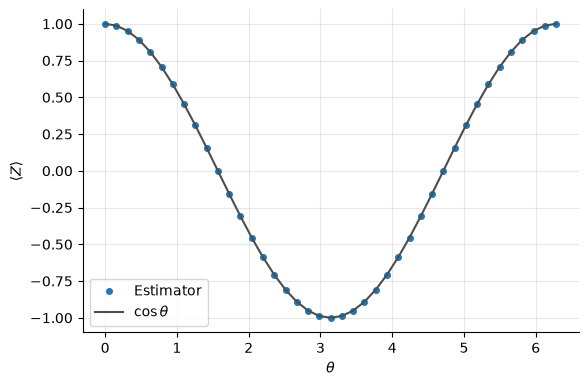

In [34]:
thetas = np.linspace(0, 2 * np.pi, 41)
values = thetas.reshape(-1, 1)  # 41 rows (one per angle), 1 column (the circuit has 1 parameter)
evs = estimator.run([(ry_circuit, Z, values)]).result()[0].data.evs
print("shape of the values:", values.shape, "  shape of the results:", evs.shape)

plt.plot(thetas, evs, "o", ms=4, label="Estimator")
plt.plot(thetas, np.cos(thetas), color="0.3", label=r"$\cos\theta$")
plt.xlabel(r"$\theta$")
plt.ylabel(r"$\langle Z \rangle$")
plt.legend()
plt.show()

**Many parameters.** `ParameterVector("θ", n)` creates $n$ parameters `θ[0]`, ..., `θ[n-1]` at once. Here is a two-qubit circuit with four of them: a layer of rotations, a CNOT, and another layer of rotations. It has the same structure as the circuit of the phase-transition notebook, with a single $R_Y$ instead of the three rotations $R_Z R_X R_Z$. We will use it in Section 12.

In [35]:
angles = ParameterVector("θ", 4)
ansatz = QuantumCircuit(2)
ansatz.ry(angles[0], 0)
ansatz.ry(angles[1], 1)
ansatz.cx(0, 1)
ansatz.ry(angles[2], 0)
ansatz.ry(angles[3], 1)
print("number of parameters:", ansatz.num_parameters)
ansatz.draw()

number of parameters: 4


┌──────────┐     ┌──────────┐
q_0: ┤ Ry(θ[0]) ├──■──┤ Ry(θ[2]) ├
     ├──────────┤┌─┴─┐├──────────┤
q_1: ┤ Ry(θ[1]) ├┤ X ├┤ Ry(θ[3]) ├
     └──────────┘└───┘└──────────┘

The values are given in the order `θ[0]`, `θ[1]`, `θ[2]`, `θ[3]`:

In [36]:
values = [0.1, 0.2, 0.3, 0.4]
print(estimator.run([(ansatz, SparsePauliOp("ZZ"), values)]).result()[0].data.evs)

0.8003313995020139


> **Careful:** Qiskit sorts the parameters of a circuit by name, and matches the values to them in that order (`ansatz.parameters` shows it). The elements of a single `ParameterVector`, as here and in the phase-transition notebook, are always in the order `θ[0]`, `θ[1]`, ... If you mix parameters with different names, check `circuit.parameters`.

## 11. Gradients: the parameter-shift rule

To find the best angles, an optimizer needs to know how the expectation value changes when each angle changes: the **gradient**. For rotation gates there is an exact trick, the **parameter-shift rule**: the derivative with respect to an angle is obtained from two more expectation values, with that angle shifted by $+\pi/2$ and by $-\pi/2$:

$$\frac{\partial E}{\partial \theta_k} = \frac{E(\boldsymbol\theta + \tfrac{\pi}{2}\mathbf e_k) - E(\boldsymbol\theta - \tfrac{\pi}{2}\mathbf e_k)}{2}.$$

Let's check it on $E(\theta) = \langle Z\rangle = \cos\theta$, whose derivative is $-\sin\theta$. The three expectation values are computed in one Estimator call, as three rows of values:

In [37]:
theta0 = 0.7
values = [[theta0], [theta0 + np.pi / 2], [theta0 - np.pi / 2]]
E, E_plus, E_minus = estimator.run([(ry_circuit, Z, values)]).result()[0].data.evs
print("parameter-shift rule:", (E_plus - E_minus) / 2)
print("exact, -sin(θ):      ", -np.sin(theta0))

parameter-shift rule: -0.6442176872376912
exact, -sin(θ):       -0.644217687237691


The two agree: unlike a finite difference, the parameter-shift rule is exact. On a real quantum computer, this is how gradients are measured.

## 12. Putting it all together: a tiny VQE

We now have all the ingredients of the **variational quantum eigensolver (VQE)**, the algorithm of the phase-transition notebook. VQE looks for the **ground state** of a Hamiltonian, the state of lowest energy:

1. a circuit with adjustable angles $\boldsymbol\theta$, the **ansatz**, prepares a trial state $|\psi(\boldsymbol\theta)\rangle$;
2. the Estimator measures its energy $E(\boldsymbol\theta) = \langle\psi(\boldsymbol\theta)|H|\psi(\boldsymbol\theta)\rangle$, and the gradient;
3. a classical optimizer changes the angles to lower the energy, and steps 2 and 3 are repeated.

The energy can never go below the true ground-state energy (the *variational principle*), so the lowest energy found is the best estimate of it.

Let's do it for the two-qubit Hamiltonian of Section 7, $H = -Z_0Z_1 - h\,(X_0 + X_1)$ with $h = 0.5$, using the four-angle ansatz of Section 10. First, the exact answer, for comparison:

In [38]:
h = 0.5
H = SparsePauliOp.from_sparse_list([("ZZ", [0, 1], -1.0), ("X", [0], -h), ("X", [1], -h)], num_qubits=2)
E_exact = np.linalg.eigvalsh(H.to_matrix())[0]  # the lowest eigenvalue
print("exact ground-state energy:", E_exact)

exact ground-state energy: -1.4142135623730951


Next, the cost function. Given the angles, it returns the energy and its gradient from the parameter-shift rule. With $n$ angles it needs $2n + 1$ energies, all computed in **one** Estimator call: one row with the angles themselves, $n$ rows with one angle shifted by $+\pi/2$, and $n$ rows with one angle shifted by $-\pi/2$. The phase-transition notebook uses the same function, in `make_cost_function`.

In [39]:
def energy_and_gradient(params, ansatz, hamiltonian):
    n = len(params)
    shifts = (np.pi / 2) * np.eye(n)  # row k: π/2 on angle k, 0 on the others
    batch = np.vstack([params, params + shifts, params - shifts])  # 2n + 1 rows
    evs = estimator.run([(ansatz, hamiltonian, batch)]).result()[0].data.evs
    energy = evs[0]
    gradient = 0.5 * (evs[1:n + 1] - evs[n + 1:])
    return energy, gradient


energy, gradient = energy_and_gradient(np.zeros(4), ansatz, H)
print("all angles 0:  energy", energy, "  gradient", gradient)

all angles 0:  energy -1.0   gradient [ 0.  -0.5 -0.5 -0.5]


Finally, the optimizer: `minimize` from SciPy, with the **L-BFGS-B** method, as in the phase-transition notebook. `args` passes the ansatz and the Hamiltonian to our function, `jac=True` tells `minimize` that the function returns the gradient as well as the energy, and the `callback` records the energy after every iteration. The starting angles are random, from a generator with a fixed *seed*, so that you get the same numbers every time.

In [40]:
rng = np.random.default_rng(1)  # fixed seed: reproducible starting angles
start = rng.uniform(0, 2 * np.pi, ansatz.num_parameters)

history = [energy_and_gradient(start, ansatz, H)[0]]  # the energy at the start
result = minimize(energy_and_gradient, start, args=(ansatz, H), jac=True, method="L-BFGS-B",
                  callback=lambda intermediate_result: history.append(intermediate_result.fun))

print(f"VQE energy:   {result.fun:.6f}   after {result.nit} iterations")
print(f"exact energy: {E_exact:.6f}")

VQE energy:   -1.414214   after 13 iterations
exact energy: -1.414214


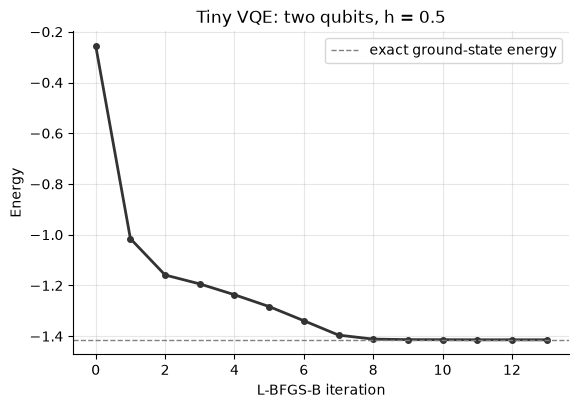

In [41]:
plt.plot(history, color="0.2", lw=2, marker="o", ms=4)
plt.axhline(E_exact, color="0.5", lw=1, ls="--", label="exact ground-state energy")
plt.xlabel("L-BFGS-B iteration")
plt.ylabel("Energy")
plt.title(f"Tiny VQE: two qubits, h = {h}")
plt.legend()
plt.show()

VQE has found the ground-state energy. The optimized angles are in `result.x`. What does the state look like?

In [42]:
show_state(ansatz.assign_parameters(result.x))

zz, x0 = estimator.run([(ansatz, [SparsePauliOp("ZZ"), SparsePauliOp("IX")], result.x)]).result()[0].data.evs
print(f"\n<Z0 Z1> = {zz:.3f}    <X0> = {x0:.3f}")

            +0.653 |00⟩    probability 0.427
            +0.271 |01⟩    probability 0.073
            +0.271 |10⟩    probability 0.073
            +0.653 |11⟩    probability 0.427

<Z0 Z1> = 0.707    <X0> = 0.707


Mostly $|00\rangle$ and $|11\rangle$ (probability 0.43 each), as in the Bell state: the interaction $-Z_0Z_1$ wants the two spins to agree. The field $-h\,(X_0+X_1)$ mixes in some $|01\rangle$ and $|10\rangle$, so that $\langle Z_0Z_1\rangle = 0.707$ is less than 1, and $\langle X_0\rangle = 0.707$ is not zero. This competition between the interaction and the field is what drives the phase transition in the next notebook. Exercise 3 shows what happens with a weaker and a stronger field.

**That's the whole VQE algorithm.** The phase-transition notebook does the same with longer chains (up to 8 qubits), the $R_Z R_X R_Z$ rotations, several random starting points, and the magnetization to tell the phases apart.

## Summary: a Qiskit cheat sheet

| To... | write |
|---|---|
| create a circuit with `N` qubits | `qc = QuantumCircuit(N)` |
| add gates | `qc.h(0)`, `qc.rx(theta, 1)`, `qc.cx(0, 1)` (angle first, then qubits) |
| draw it | `qc.draw()` |
| get its exact state | `Statevector(qc)` |
| ... and the probabilities | `Statevector(qc).probabilities_dict()` |
| measure it with shots | `qc.measure_all()`, then `StatevectorSampler().run([qc], shots=1000).result()[0].data.meas.get_counts()` |
| write an observable | `SparsePauliOp("IZ")`, or `SparsePauliOp.from_sparse_list([("ZZ", [0, 1], -1.0)], num_qubits=N)` |
| combine observables | `A + B`, `2 * A`, `(A @ B).simplify()`, `A.to_matrix()` |
| exact expectation value | `Statevector(qc).expectation_value(op).real` |
| expectation values with the Estimator | `StatevectorEstimator().run([(qc, op)]).result()[0].data.evs` |
| ... several observables | `run([(qc, [op1, op2])])` |
| ... with parameter values | `run([(qc, op, values)])`, with one row of `values` per set of angles |
| create parameters | `Parameter("θ")`, `ParameterVector("θ", n)` |
| count them / give them values | `qc.num_parameters`, `qc.assign_parameters(values)` |
